In [4]:
print("Customer Chrun Project is ready!")

Customer Chrun Project is ready!


In [5]:
import pandas as pd

file_path = "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 7043
Number of columns: 21


In [7]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [9]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
(df["TotalCharges"].astype(str).str.strip()=="").sum()

np.int64(11)

In [11]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")

In [12]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [13]:
df[df["TotalCharges"].isnull()][["customerID","tenure","MonthlyCharges","TotalCharges","Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [14]:
df["TotalCharges"]=df["TotalCharges"].fillna(0)

In [15]:
df["TotalCharges"].isnull().sum()

np.int64(0)

In [16]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [19]:
churn_rate=df["Churn"].value_counts(normalize=True) * 100
print("Churn Rate:")
print(churn_rate)

Churn Rate:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [20]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [21]:
churn_by_contract=pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100
churn_by_contract

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [22]:
churn_by_internet=pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100
churn_by_internet

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


In [23]:
churn_by_payment=pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100
churn_by_payment

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


In [24]:
df.to_csv("../data/processed/telco_churn_cleaned.csv",index=False)
print("Cleared dataset saved successfully!")

Cleared dataset saved successfully!


In [26]:
import matplotlib.pyplot as plt

In [27]:
import matplotlib.pyplot as plt
print("Matplotlib is working")

Matplotlib is working


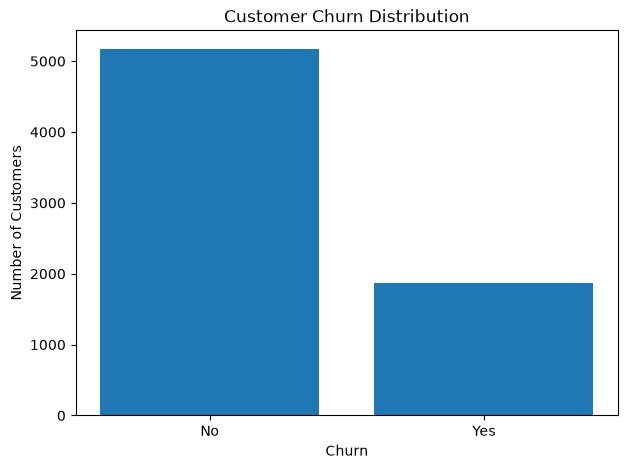

In [28]:
churn_counts =df["Churn"].value_counts()
plt.figure(figsize=(7,5))
plt.bar(churn_counts.index,churn_counts.values)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

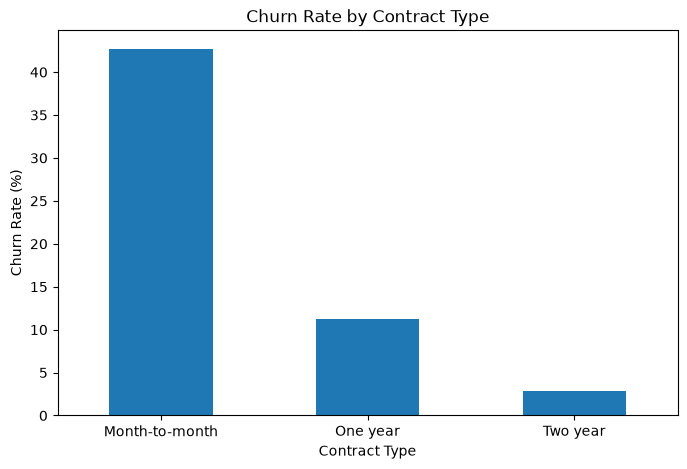

In [29]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [30]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 60, float("inf")],
    labels=["0-12 Months", "13-24 Months", "25-48 Months", "49-60 Months", "61+ Months"]
)

df["TenureGroup"].value_counts().sort_index()

TenureGroup
0-12 Months     2186
13-24 Months    1024
25-48 Months    1594
49-60 Months     832
61+ Months      1407
Name: count, dtype: int64

In [31]:
tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

tenure_churn

Churn,No,Yes
TenureGroup,,
0-12 Months,52.561757,47.438243
13-24 Months,71.289062,28.710938
25-48 Months,79.611041,20.388959
49-60 Months,85.576923,14.423077
61+ Months,93.390192,6.609808


In [32]:
df["MonthlyChargeGroup"] = pd.qcut(
    df["MonthlyCharges"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"]
)

df["MonthlyChargeGroup"].value_counts().sort_index()

MonthlyChargeGroup
Low          1762
Medium       1766
High         1757
Very High    1758
Name: count, dtype: int64

In [33]:
charge_churn = pd.crosstab(
    df["MonthlyChargeGroup"],
    df["Churn"],
    normalize="index"
) * 100

charge_churn

Churn,No,Yes
MonthlyChargeGroup,,
Low,88.762770,11.237230
Medium,75.424689,24.575311
High,62.492886,37.507114
Very High,67.121729,32.878271


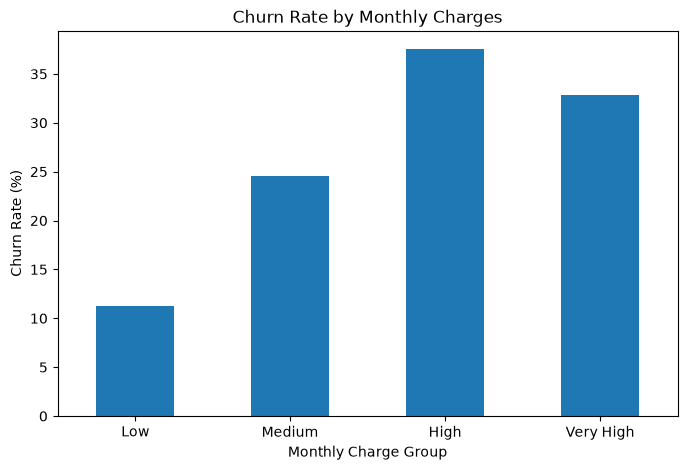

In [34]:
charge_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Monthly Charges")
plt.xlabel("Monthly Charge Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [35]:
ml_df = df.copy()

ml_df = ml_df.drop(
    columns=["customerID", "TenureGroup", "MonthlyChargeGroup"]
)

print("ML dataset created!")
print("Rows:", ml_df.shape[0])
print("Columns:", ml_df.shape[1])

ML dataset created!
Rows: 7043
Columns: 20


In [36]:
ml_df["Churn"] = ml_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print(ml_df["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [37]:
ml_df = pd.get_dummies(
    ml_df,
    drop_first=True,
    dtype=int
)

print("Categorical features encoded successfully!")
print("Rows:", ml_df.shape[0])
print("Columns:", ml_df.shape[1])

Categorical features encoded successfully!
Rows: 7043
Columns: 31


In [38]:
X = ml_df.drop("Churn", axis=1)
y = ml_df["Churn"]

print("Features (X):", X.shape)
print("Target (y):", y.shape)

Features (X): (7043, 30)
Target (y): (7043,)


In [39]:
from sklearn.model_selection import train_test_split

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 30)
Testing data: (1409, 30)


In [41]:
from sklearn.linear_model import LogisticRegression

In [42]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Logistic Regression model created!")

Logistic Regression model created!


In [43]:
logistic_model.fit(X_train, y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


c:\Users\k7036\OneDrive\Desktop\Customer_Churn_Project\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [44]:
x_train.select_dtypes(exclude="number").columns

NameError: name 'x_train' is not defined

In [43]:
x_train.isnull().sum().sort_values(ascending=False).head(10)

NameError: name 'x_train' is not defined

In [3]:
X_train.isnull().sum().sort_values(ascending=False).head(10)

NameError: name 'X_train' is not defined

In [45]:
from sklearn.model_selection import train_test_split

print("scikit-learn is working in the notebook!")

scikit-learn is working in the notebook!


In [46]:
print("Total missing values in X_train:", X_train.isnull().sum().sum())
print("Total missing values in X_test:", X_test.isnull().sum().sum())

Total missing values in X_train: 0
Total missing values in X_test: 0


In [47]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [48]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


c:\Users\k7036\OneDrive\Desktop\Customer_Churn_Project\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [49]:
y_pred = logistic_model.predict(X_test)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

Predictions generated successfully!
Number of predictions: 1409


In [50]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Logistic Regression Accuracy: 80.48 %

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.65      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409



In [51]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Logistic Regression Accuracy: 80.48 %

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.65      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409



In [52]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

print("Decision Tree model created successfully!")

Decision Tree model created successfully!


In [53]:
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [54]:
y_pred_dt = decision_tree_model.predict(X_test)

print("Decision Tree predictions generated successfully!")
print("Number of predictions:", len(y_pred_dt))

Decision Tree predictions generated successfully!
Number of predictions: 1409


In [55]:
from sklearn.metrics import accuracy_score, classification_report

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")
print("\nDecision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 79.42 %

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1035
           1       0.63      0.54      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409



In [56]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [57]:
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [58]:
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest predictions generated successfully!")
print("Number of predictions:", len(y_pred_rf))

Random Forest predictions generated successfully!
Number of predictions: 1409


In [59]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")
print("\nRandom Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 80.62 %

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.67      0.53      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



In [60]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

print("XGBoost model created successfully!")

XGBoost model created successfully!


In [61]:
xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [62]:
y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost predictions generated successfully!")
print("Number of predictions:", len(y_pred_xgb))

XGBoost predictions generated successfully!
Number of predictions: 1409


In [63]:
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

print("XGBoost Accuracy:", round(xgb_accuracy * 100, 2), "%")
print("\nXGBoost Classification Report:")
print(classification_report(y_test, y_pred_xgb))

XGBoost Accuracy: 79.63 %

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1035
           1       0.64      0.53      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [64]:
from sklearn.metrics import precision_score, recall_score, f1_score

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ]
})

model_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.804826,0.654206,0.561497,0.604317
1,Decision Tree,0.794180,0.631250,0.540107,0.582133
2,Random Forest,0.806246,0.668896,0.534759,0.594354
3,XGBoost,0.796309,0.640777,0.529412,0.579795


In [65]:
best_model = model_results.loc[
    model_results["F1 Score"].idxmax()
]

print("Best Model Based on F1 Score:")
print(best_model)

Best Model Based on F1 Score:
Model        Logistic Regression
Accuracy                0.804826
Precision               0.654206
Recall                  0.561497
F1 Score                0.604317
Name: 0, dtype: object


In [66]:
from sklearn.metrics import roc_auc_score

# Get probability of Churn = 1
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

roc_auc_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_dt),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_xgb)
    ]
})

roc_auc_results

,Model,ROC-AUC
0,Logistic Regression,0.842729
1,Decision Tree,0.826704
2,Random Forest,0.843640
3,XGBoost,0.841884


Best Model: Logistic Regression

Confusion Matrix:
[[924 111]
 [164 210]]


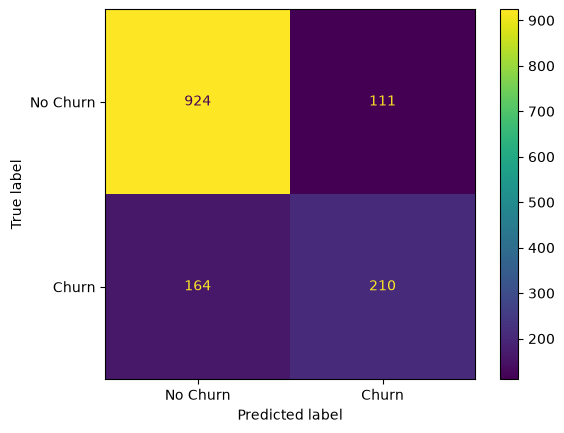

In [67]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_model_name = best_model["Model"]

if best_model_name == "Logistic Regression":
    best_predictions = y_pred
elif best_model_name == "Decision Tree":
    best_predictions = y_pred_dt
elif best_model_name == "Random Forest":
    best_predictions = y_pred_rf
else:
    best_predictions = y_pred_xgb

cm = confusion_matrix(y_test, best_predictions)

print("Best Model:", best_model_name)
print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()

In [68]:
# Calculate important business metrics

tn, fp, fn, tp = 924, 111, 164, 210

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
accuracy_cm = (tp + tn) / (tp + tn + fp + fn)

print("Sensitivity (Recall):", round(sensitivity * 100, 2), "%")
print("Specificity:", round(specificity * 100, 2), "%")
print("Accuracy:", round(accuracy_cm * 100, 2), "%")

Sensitivity (Recall): 56.15 %
Specificity: 89.28 %
Accuracy: 80.48 %


In [69]:
# Analyze Logistic Regression feature importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": logistic_model.coef_[0]
})

feature_importance["Absolute_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

feature_importance.head(15)

,Feature,Coefficient,Absolute_Coefficient
25,Contract_Two year,-1.325214,1.325214
10,InternetService_Fiber optic,0.742896,0.742896
24,Contract_One year,-0.684531,0.684531
13,OnlineSecurity_Yes,-0.437039,0.437039
7,PhoneService_Yes,-0.430754,0.430754
19,TechSupport_Yes,-0.389446,0.389446
28,PaymentMethod_Electronic check,0.387787,0.387787
26,PaperlessBilling_Yes,0.376456,0.376456
9,MultipleLines_Yes,0.274968,0.274968
6,Dependents_Yes,-0.219680,0.219680


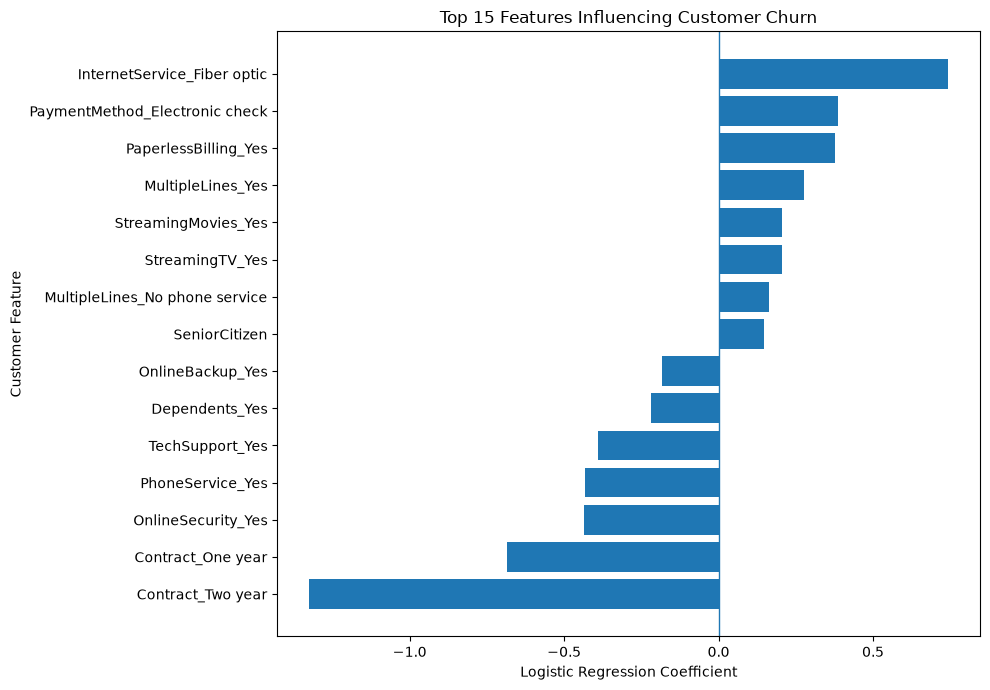

In [70]:
# Visualize the most important churn factors

top_features = feature_importance.head(15).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(x=0, linewidth=1)

plt.title("Top 15 Features Influencing Customer Churn")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Customer Feature")

plt.tight_layout()
plt.show()

In [71]:
import joblib

# Save the best model
model_path = "../models/logistic_regression_model.joblib"

joblib.dump(logistic_model, model_path)

print("Model saved successfully!")
print("Saved at:", model_path)

Model saved successfully!
Saved at: ../models/logistic_regression_model.joblib


In [72]:
# Save preprocessing information for the dashboard

preprocessing_data = {
    "feature_columns": X_train.columns.tolist(),
    "imputer": imputer
}

preprocessing_path = "../models/preprocessing.joblib"

joblib.dump(preprocessing_data, preprocessing_path)

print("Preprocessing information saved successfully!")
print("Saved at:", preprocessing_path)
print("Number of model features:", len(X_train.columns))

NameError: name 'imputer' is not defined

In [73]:
from sklearn.impute import SimpleImputer

# Recreate the imputer
imputer = SimpleImputer(strategy="median")

# Fit it on the training data
imputer.fit(X_train)

print("Imputer recreated successfully!")

Imputer recreated successfully!


In [74]:
# Save preprocessing information for the dashboard

preprocessing_data = {
    "feature_columns": X_train.columns.tolist(),
    "imputer": imputer
}

preprocessing_path = "../models/preprocessing.joblib"

joblib.dump(preprocessing_data, preprocessing_path)

print("Preprocessing information saved successfully!")
print("Saved at:", preprocessing_path)
print("Number of model features:", len(X_train.columns))

Preprocessing information saved successfully!
Saved at: ../models/preprocessing.joblib
Number of model features: 30


In [75]:
import os

print("Model file exists:",
      os.path.exists("../models/logistic_regression_model.joblib"))

print("Preprocessing file exists:",
      os.path.exists("../models/preprocessing.joblib"))

Model file exists: True
Preprocessing file exists: True
